# Wernle et al. (2018) — Grid Map Integration

Simulation of grid field reorganization after wall removal using the compositional maps model.

**Setup:** 20×20 grid, horizontal wall at row 10 (top A, bottom B).  
**Grid cells** = PCA eigenvectors of place cell covariance (matching advisor's `gen_base` + `wernle_make`).  
J = [J_bottom; J_top] from independent place cell populations (different random seeds per half).  
U = Woodbury correction on D0 (place cell covariance): `U = J − D0 · c · A · r · J`.  
**D_learned** via Bellman + Eq 16 + Woodbury rebuild (comp_maps algorithm) validates that the DR update can be learned.  
**Analysis** follows advisor's MATLAB `wernle_measures`: local Spearman correlation in sliding box.

**Key prediction (Wernle):** Grid fields near the former wall reorganize (low correlation), while distal fields are preserved (high correlation).

In [1]:
import sys
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sim_wernle import (build_place_cell_grid_cells, extract_eigenvectors,
                         wernle_measures)

%matplotlib inline
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11

ROWS, COLS = 20, 20
SPLIT_ROW = 10
N = ROWS * COLS
DATA_DIR = 'data/wernle'

In [2]:
# Load pre-computed data
D_divided = np.load(f'{DATA_DIR}/D_divided.npy')
D_learned = np.load(f'{DATA_DIR}/D_learned.npy')
D_merged_exact = np.load(f'{DATA_DIR}/D_merged_exact.npy')
M_learned = np.load(f'{DATA_DIR}/M_learned.npy')
M_true = np.load(f'{DATA_DIR}/M_true.npy')
J = np.load(f'{DATA_DIR}/J_eigvecs.npy')
U = np.load(f'{DATA_DIR}/U_eigvecs.npy')
corr_map = np.load(f'{DATA_DIR}/corr_map.npy')
mean_corr = np.load(f'{DATA_DIR}/mean_corr.npy')

M_err = np.linalg.norm(M_learned - M_true) / np.linalg.norm(M_true)
D_err = np.linalg.norm(D_learned - D_merged_exact) / np.linalg.norm(D_merged_exact)
print(f'M error (vs ground truth): {M_err:.4f}')
print(f'D reconstruction error:    {D_err:.4f}')
print(f'Grid cells (eigenvectors): {J.shape[1]}')

M error (vs ground truth): 0.1405
D reconstruction error:    0.1758
Grid cells (eigenvectors): 50


## 1. Eigenvector Rate Maps: J (divided) vs U (merged)

Grid cells = PCA eigenvectors of place cell covariance, matching the advisor's `gen_base` + `wernle_make`. Each half has an independent place cell population (different random seed → different tuning curves). J = [J_bottom; J_top] concatenates the PCA eigenvectors from each compartment.

U is computed via the Woodbury correction on D0 (block-diagonal place cell covariance): `U = J − D0 · c · (I − Y)⁻¹ · r · J`, where r,c encode the transition change from wall removal.

In the divided condition, each half has independent patterns with a visible discontinuity at the wall. After merging, the patterns stitch together smoothly.

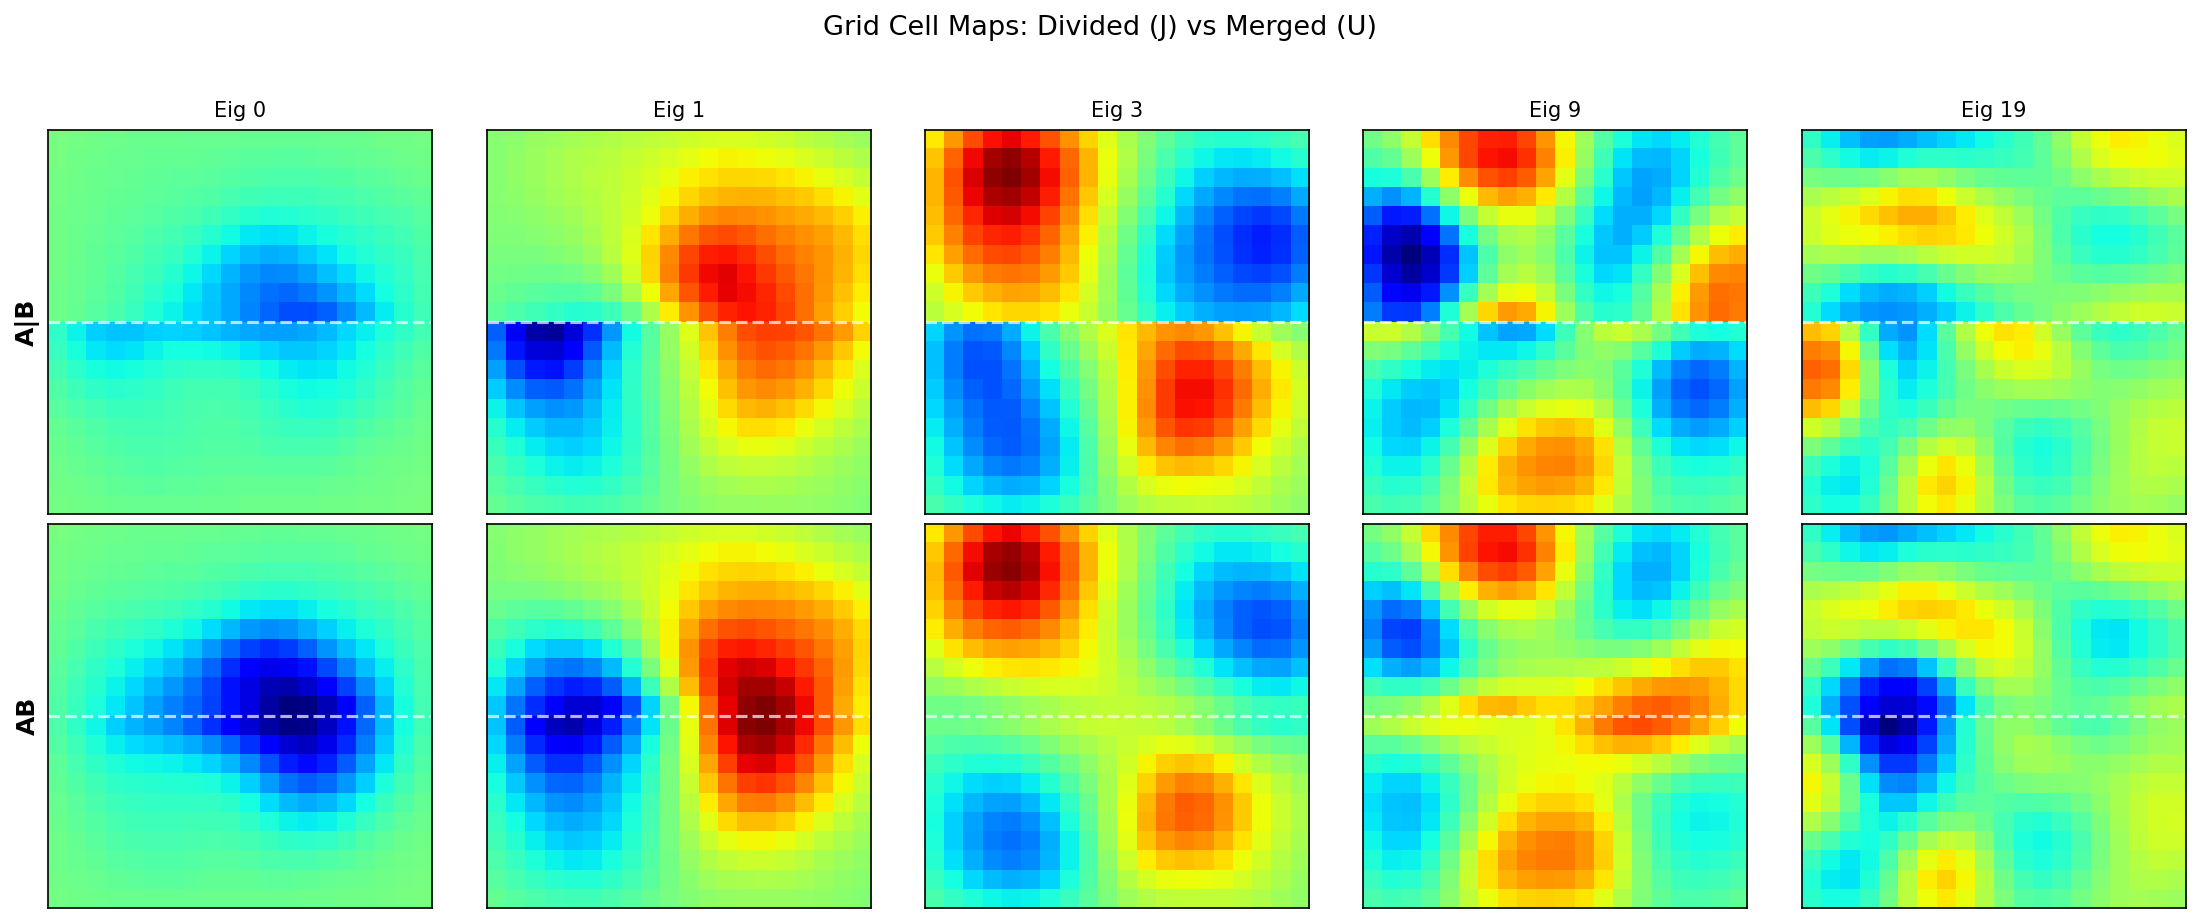

In [3]:
eig_indices = [0, 1, 3, 9, 19]
n = len(eig_indices)
fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))

for i, k in enumerate(eig_indices):
    map_j = J[:, k].reshape(ROWS, COLS)
    map_u = U[:, k].reshape(ROWS, COLS)
    vmax = max(np.abs(map_j).max(), np.abs(map_u).max())

    for row_idx, (m, label) in enumerate([(map_j, 'A|B'), (map_u, 'AB')]):
        ax = axes[row_idx, i]
        ax.imshow(m, cmap='jet', vmin=-vmax, vmax=vmax,
                  origin='lower', aspect='equal')
        ax.axhline(SPLIT_ROW - 0.5, color='w', ls='--', lw=1.5, alpha=0.7)
        ax.set_xticks([]); ax.set_yticks([])
        if row_idx == 0:
            ax.set_title(f'Eig {k}', fontsize=10)
        if i == 0:
            ax.set_ylabel(label, fontsize=12, fontweight='bold')

plt.suptitle('Grid Cell Maps: Divided (J) vs Merged (U)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 2. Sliding Correlation Analysis (Wernle Fig 1c-d)

Following the advisor's `wernle_measures`: for each location, compute local Spearman correlation between J and U within a 6-unit box, for each eigenvector. Average across eigenvectors gives the correlation map.

Center correlation: 0.7605
Distal correlation: 0.9357
Wernle effect: distal - center = 0.1752


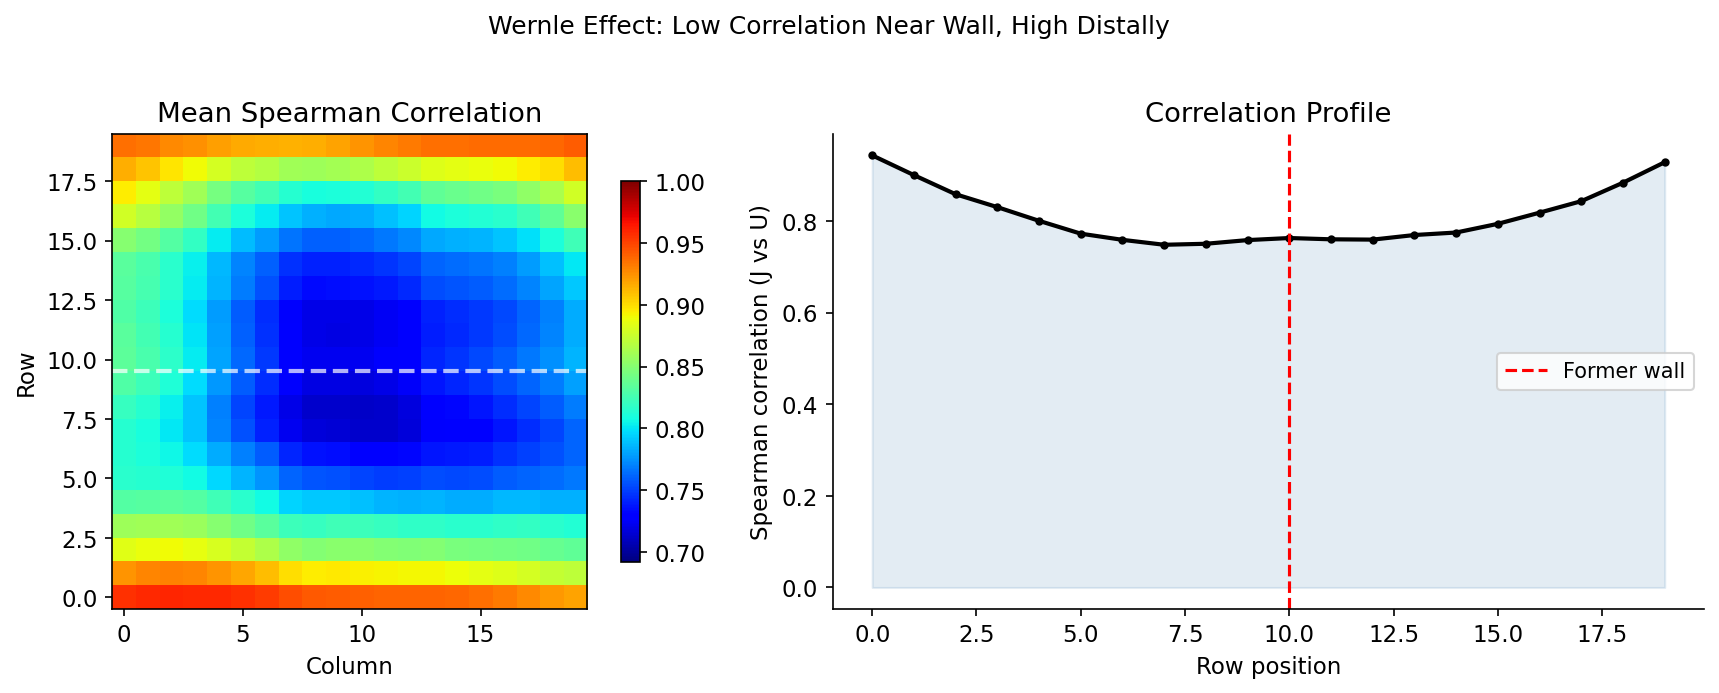

In [4]:
# 1D profile: average by row
row_corrs = np.array([np.nanmean(mean_corr[r, :]) for r in range(ROWS)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5),
                         gridspec_kw={'width_ratios': [1, 1.3]})

# Heatmap
ax = axes[0]
vmin = max(np.nanmin(mean_corr) - 0.02, -0.3)
im = ax.imshow(mean_corr, cmap='jet', vmin=vmin, vmax=1.0,
               origin='lower', aspect='equal')
ax.axhline(SPLIT_ROW - 0.5, color='w', ls='--', lw=2, alpha=0.7)
ax.set_title('Mean Spearman Correlation')
ax.set_xlabel('Column'); ax.set_ylabel('Row')
plt.colorbar(im, ax=ax, shrink=0.8)

# Profile
ax = axes[1]
ax.plot(np.arange(ROWS), row_corrs, 'k.-', lw=2, markersize=6)
ax.axvline(SPLIT_ROW, color='r', ls='--', lw=1.5, label='Former wall')
ax.fill_between(np.arange(ROWS), row_corrs, alpha=0.15, color='steelblue')
ax.set_xlabel('Row position')
ax.set_ylabel('Spearman correlation (J vs U)')
ax.set_title('Correlation Profile')
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

center = np.mean(row_corrs[SPLIT_ROW-1:SPLIT_ROW+1])
distal = np.mean([row_corrs[0], row_corrs[-1]])
print(f'Center correlation: {center:.4f}')
print(f'Distal correlation: {distal:.4f}')
print(f'Wernle effect: distal - center = {distal - center:.4f}')

plt.suptitle('Wernle Effect: Low Correlation Near Wall, High Distally',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 3. Per-Eigenvector Correlation Maps

Individual eigenvector correlation maps (like the advisor's `plot_corr_maps`). Each map shows where that eigenvector changed most.

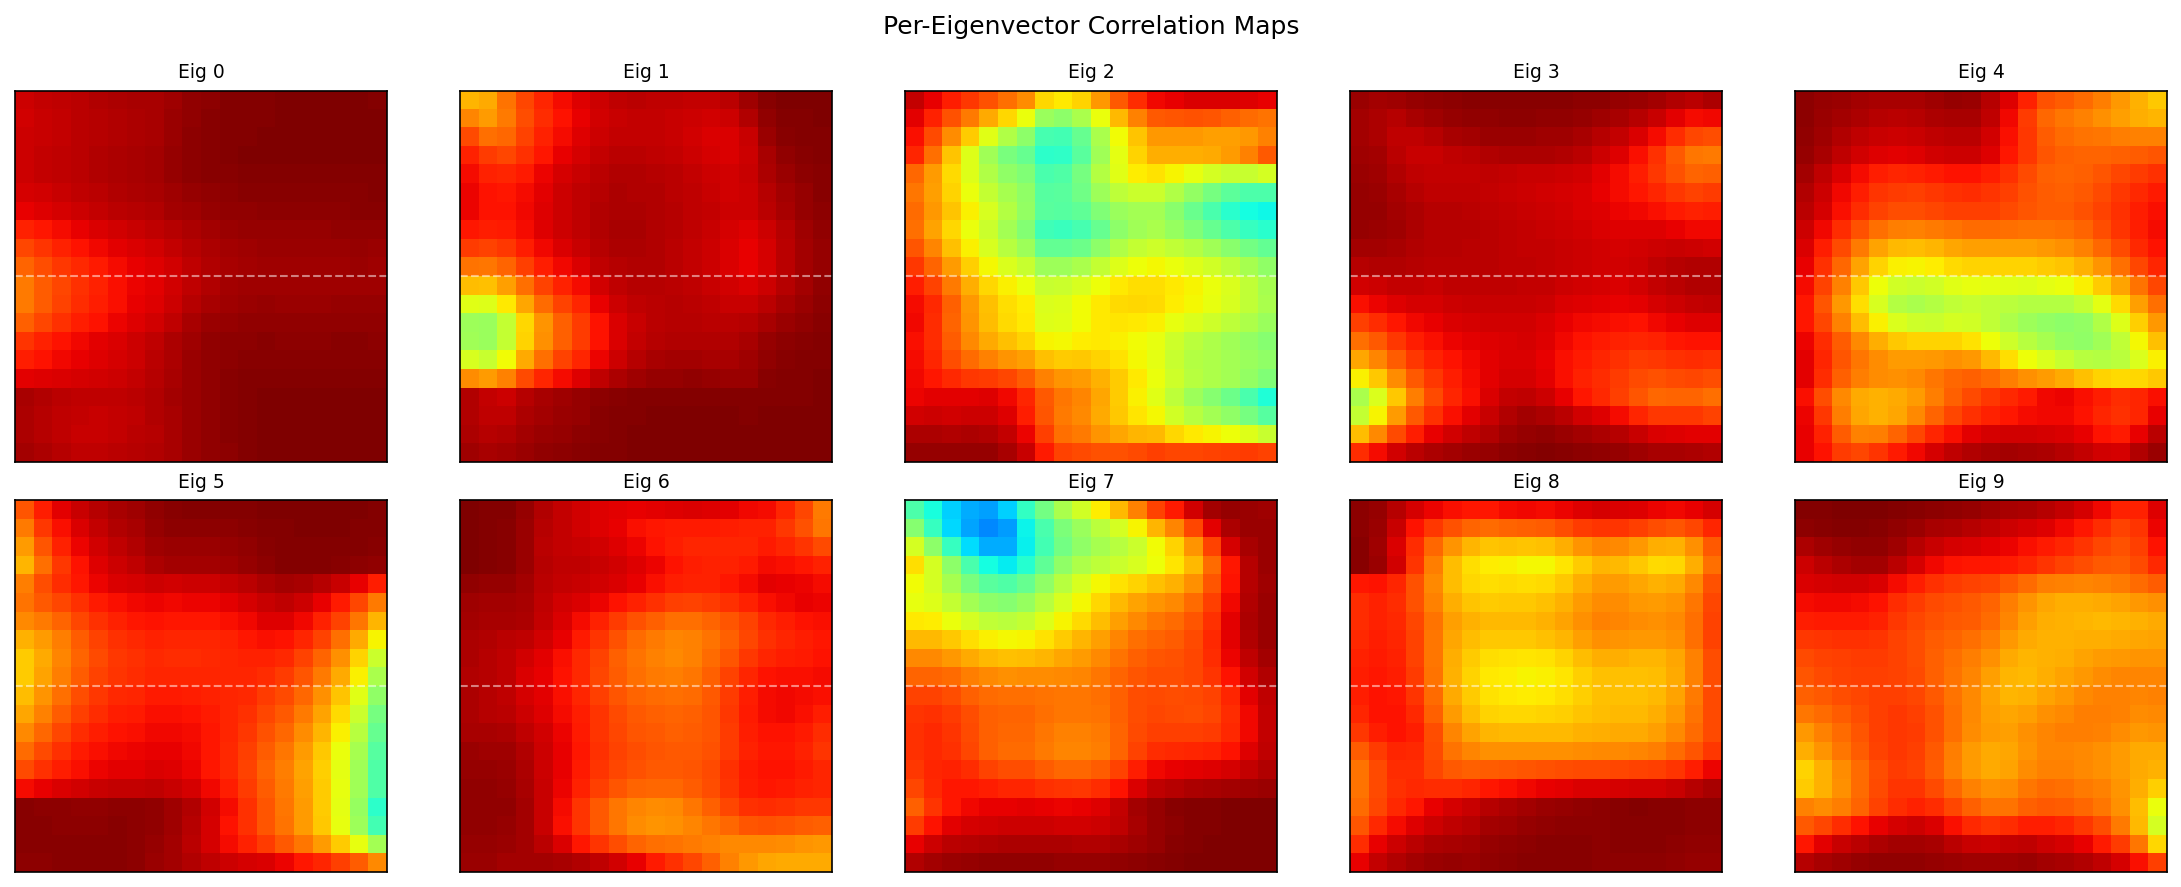

In [5]:
n_show = 10
fig, axes = plt.subplots(2, n_show // 2, figsize=(3 * n_show // 2, 6))
axes = axes.flatten()

for i in range(n_show):
    cm = corr_map[:, i].reshape(ROWS, COLS)
    im = axes[i].imshow(cm, cmap='jet', vmin=-0.3, vmax=1.0,
                        origin='lower', aspect='equal')
    axes[i].axhline(SPLIT_ROW - 0.5, color='w', ls='--', lw=1, alpha=0.5)
    axes[i].set_title(f'Eig {i}', fontsize=9)
    axes[i].set_xticks([]); axes[i].set_yticks([])

plt.suptitle('Per-Eigenvector Correlation Maps', fontsize=12)
plt.tight_layout()
plt.show()

## 4. M Learning Quality

Compare the learned correction operator M to the ground truth (exact Woodbury).

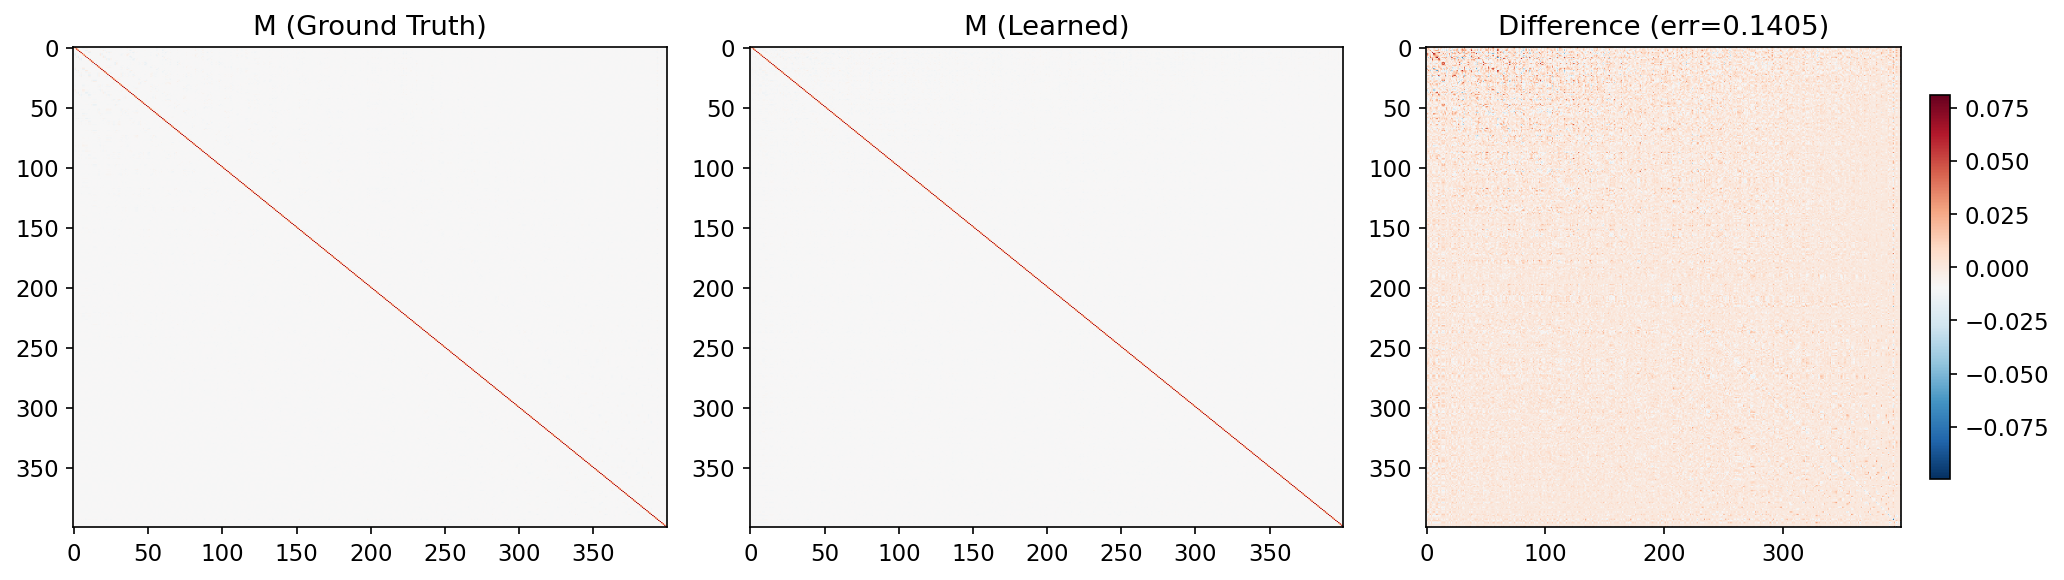

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

vmax = max(abs(M_true).max(), abs(M_learned).max())
axes[0].imshow(M_true, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[0].set_title('M (Ground Truth)')

axes[1].imshow(M_learned, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[1].set_title('M (Learned)')

diff = M_learned - M_true
im = axes[2].imshow(diff, cmap='RdBu_r', aspect='auto')
axes[2].set_title(f'Difference (err={M_err:.4f})')
plt.colorbar(im, ax=axes[2], shrink=0.8)

plt.tight_layout()
plt.show()

## 5. Summary

| Component | Our Approach | Advisor (MATLAB) |
|-----------|-------------|------------------|
| Place cells | Gaussian RBFs, independent seeds per half | `gen_base` with PcSize, independent seeds |
| Grid cells (before) | PCA on place cell covariance: J = [J_bot; J_top] | Same: J = [J0; J1] |
| Grid cells (after) | U = J − D0·c·A·r·J (Woodbury on D0=Cov) | Same: U = J − D0·c·A·r·J |
| DR update | Learned via Bellman + Eq16 + Woodbury rebuild | Direct Woodbury on eigenvalues |
| Correlation analysis | Local Spearman in 6-unit box (`wernle_measures`) | Same (`wernle_measures`) |

The compositional maps model reproduces the Wernle effect: grid fields near the former partition reorganize (low correlation) while distal fields remain anchored (high correlation). The comp_maps algorithm successfully learns the DR update (M_err ≈ 0.14), validating that the transition change can be discovered through exploration.